In [1]:
import sys
sys.path.append("./../") 

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

from scripts.utils import load_array
from scripts.cshap import DWTDecomposition, EMDDecomposition, CustomDecomposition
from scripts.cshap.plotting import plot_shap_decomposition

This notebook contains code for generating plots for the global and local explanations given precalculated C-SHAP values.

<h2> Initialization </h2>
Start with initialization and loading the data and SHAP values.

In [2]:
colors = ["#A338C4", '#248EF1', "#29BA10", '#F68D0E', '#F12476']

In [3]:
# Initialize settings
dataset = 'opportunity_uni'     # Dataset name
decomposition_def = 'trend+bias+scale*(low_freq+var*high_freq)'         # Definition for decomposition  
noise_sigma=1                                                           # If custom decomposition, threshold for low frequency
max_imfs = 4                                                            # If EMD, number of IMFs to include
dwt_level = 3                                                           # If DWT, number of levels to include
cnn = False                                                             # If False, show GRU results, if True show CNN results

# Number of sets of C-SHAP values calculated - will be averaged over these sets
# ensure the sets are named in an iterable fashion, for example shap_values0, shap_values1, ...
n_runs = 10                                                             

In [4]:
data_path = './../data/prepared/' + dataset
if cnn:
    shap_path = './../data/cshap/' + dataset + '/uni_channel/cnn/' + decomposition_def
else:
    shap_path = './../data/cshap/' + dataset + '/uni_channel/' + decomposition_def
shap_path = shap_path.replace('*', 'x')

In [5]:
# Mapping between labels and targets for the dataset
if dataset == 'fordA':
    class_dict = {0: 'Normal', 1: 'Anomalous'}
    var_window_size = 50                                                    # If custom decomposition, window size for variance
    t = np.linspace(0, 499, 500)                                               # Time range to plot against for local explanations
elif dataset == 'opportunity_uni':
    class_dict = {0:'Stand', 1:'Walk', 2:'Sit', 3:'Lie'}
    var_window_size = 27                                                    # If custom decomposition, window size for variance
    t = np.linspace(0, 3, 90)
elif dataset == 'turbofan':
    class_dict = None
    var_window_size = 30                                                    # If custom decomposition, window size for variance
    t = np.linspace(0, 99, 100)                                               # Time range to plot against for local explanations

In [6]:
# Load prepared data
# Signals
X_train = load_array(data_path + '/X_train.pkl')
X_test = load_array(data_path +  '/X_test.pkl')

# Targets
y_train = load_array(data_path +  '/y_train.pkl')
y_test = load_array(data_path +  '/y_test.pkl')

# Ensure proper shape
if len(X_train.shape) == 2:
    X_train = X_train[:, :, None]
    X_test = X_test[:, :, None]

In [7]:
# Load SHAP and base values for each run
shap_values_list = [None] * n_runs
base_values_list = [None] * n_runs
for i in range(n_runs):
    shap_values_list[i] = load_array(shap_path + '/shap_values' + str(i) + '.pkl')
    base_values_list[i] = load_array(shap_path + '/base_values' + str(i) + '.pkl')
shap_values_list = np.array(shap_values_list)

In [8]:
# Initialize selected decomposition using given parameters
if decomposition_def == 'EMD':
    decomposition = EMDDecomposition(max_imfs=max_imfs)
elif decomposition_def == 'DWT':
    decomposition = DWTDecomposition(level=dwt_level)
else:
    decomposition = CustomDecomposition(decomposition_def, noise_sigma=noise_sigma, var_window_size=var_window_size)

In [9]:
# Set names to use for components
if decomposition_def == 'DWT' or decomposition_def == 'EMD':
    components = decomposition.component_names
elif dataset == 'fordA':
    components = ['Scale', 'Low\nfrequency', 'Variance', 'High\nfrequency']
else:
    components = ['Trend', 'Bias', 'Scale', 'Low\nfrequency', 'Variance', 'High\nfrequency']

<h2>Global explanations</h2>

In [10]:
# Normalize SHAP values
norm_shap_values_list = np.array([(s - np.mean(s)) / np.std(s) for s in shap_values_list])

In [11]:
# Find mean absolute SHAP values
shap_values_abs = np.abs(norm_shap_values_list)
shap_values_mean_per = np.mean(shap_values_abs, axis=(1, 3))

shap_values_mean = np.mean(shap_values_mean_per, axis=0)        # Find mean over runs
shap_values_std = np.std(shap_values_mean_per, axis=0)          # Find std over runs

Text(0, 0.5, 'Concept')

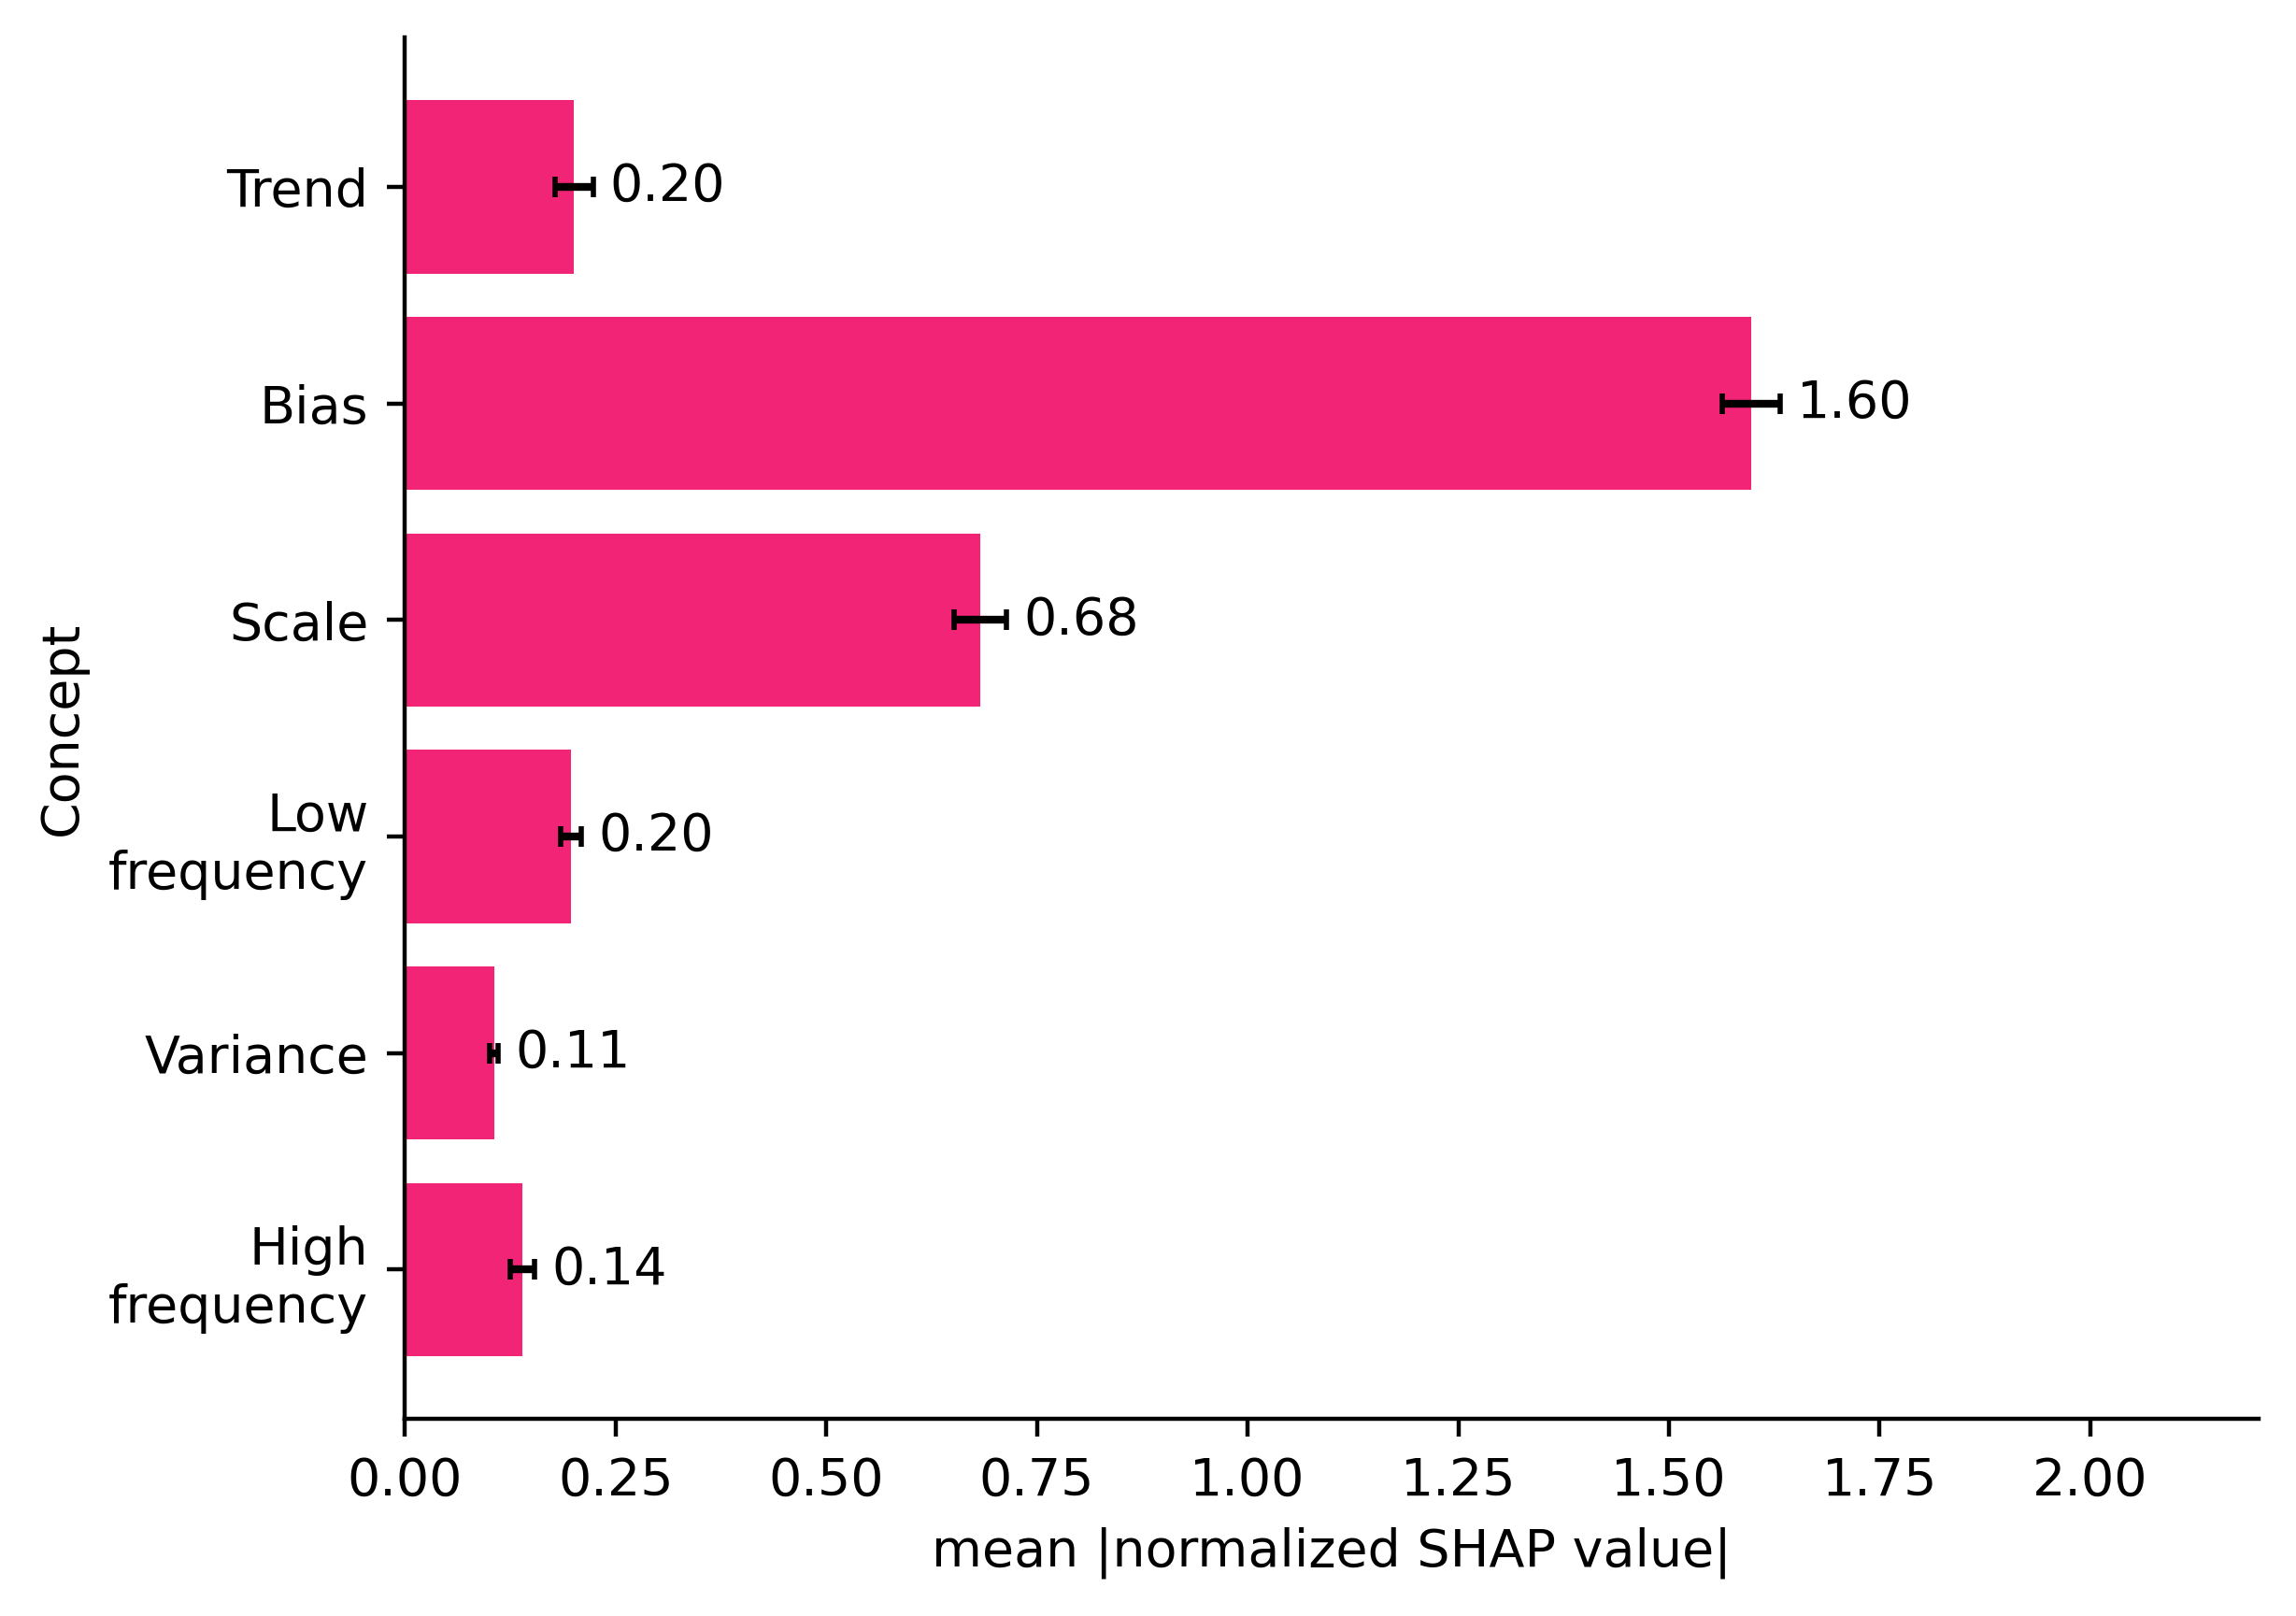

In [12]:
# Plot global explanation as average and standard deviation over the given runs
fig, ax = plt.subplots(dpi=400)

y_pos = np.arange(len(components))  # For y axis plotting use list 0, ..., number of components
plt.xlim(0, 2.2)                    # Manually set horizontal limits

ax.barh(y_pos, shap_values_mean, align='center', capsize=2, color=colors[-1], xerr=shap_values_std)  # Plot bar
ax.set_yticks(y_pos, labels=components)         # Set component names as y ticks

delta = 0.02                                    # Add text with SHAP values, delta controls space between bars and text
for i, v in enumerate(shap_values_mean):
    ax.text(v + shap_values_std[i] + delta, i, '{0:.2f}'.format(v),  verticalalignment='center')

ax.invert_yaxis()                               # Start with first component

# Remove spines
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)

# Figure annotations
ax.set_xlabel('Performance')
ax.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
plt.xlabel('mean |normalized SHAP value|')
plt.ylabel('Concept')

<h2>Local explanations</h2>

In [13]:
# Get SHAP and base values for a single run
shap_values, base_values = shap_values_list[0], base_values_list[0]

In [14]:
# Manually set verticle limits for signal and component plots
ylims = [[-4.2, 4.2] for _ in range(len(decomposition.component_names) + 1)]

In [15]:
sample_select = 67                      # Select sample to generate explanation for

if dataset in ['opportunity_uni', 'fordA']:         # If classification task
    class_select = y_test[sample_select]    # Class to generate explanation for
    class_label_selected = class_dict[class_select]
    y_pred = (np.sum(shap_values, axis=1) + base_values[0])[sample_select, class_select]    # Get model prediction
else:
    class_label_selected = None
x_components = decomposition.decompose(t, X_test[sample_select][None, :, :])[0]                  # Get components from decomposition

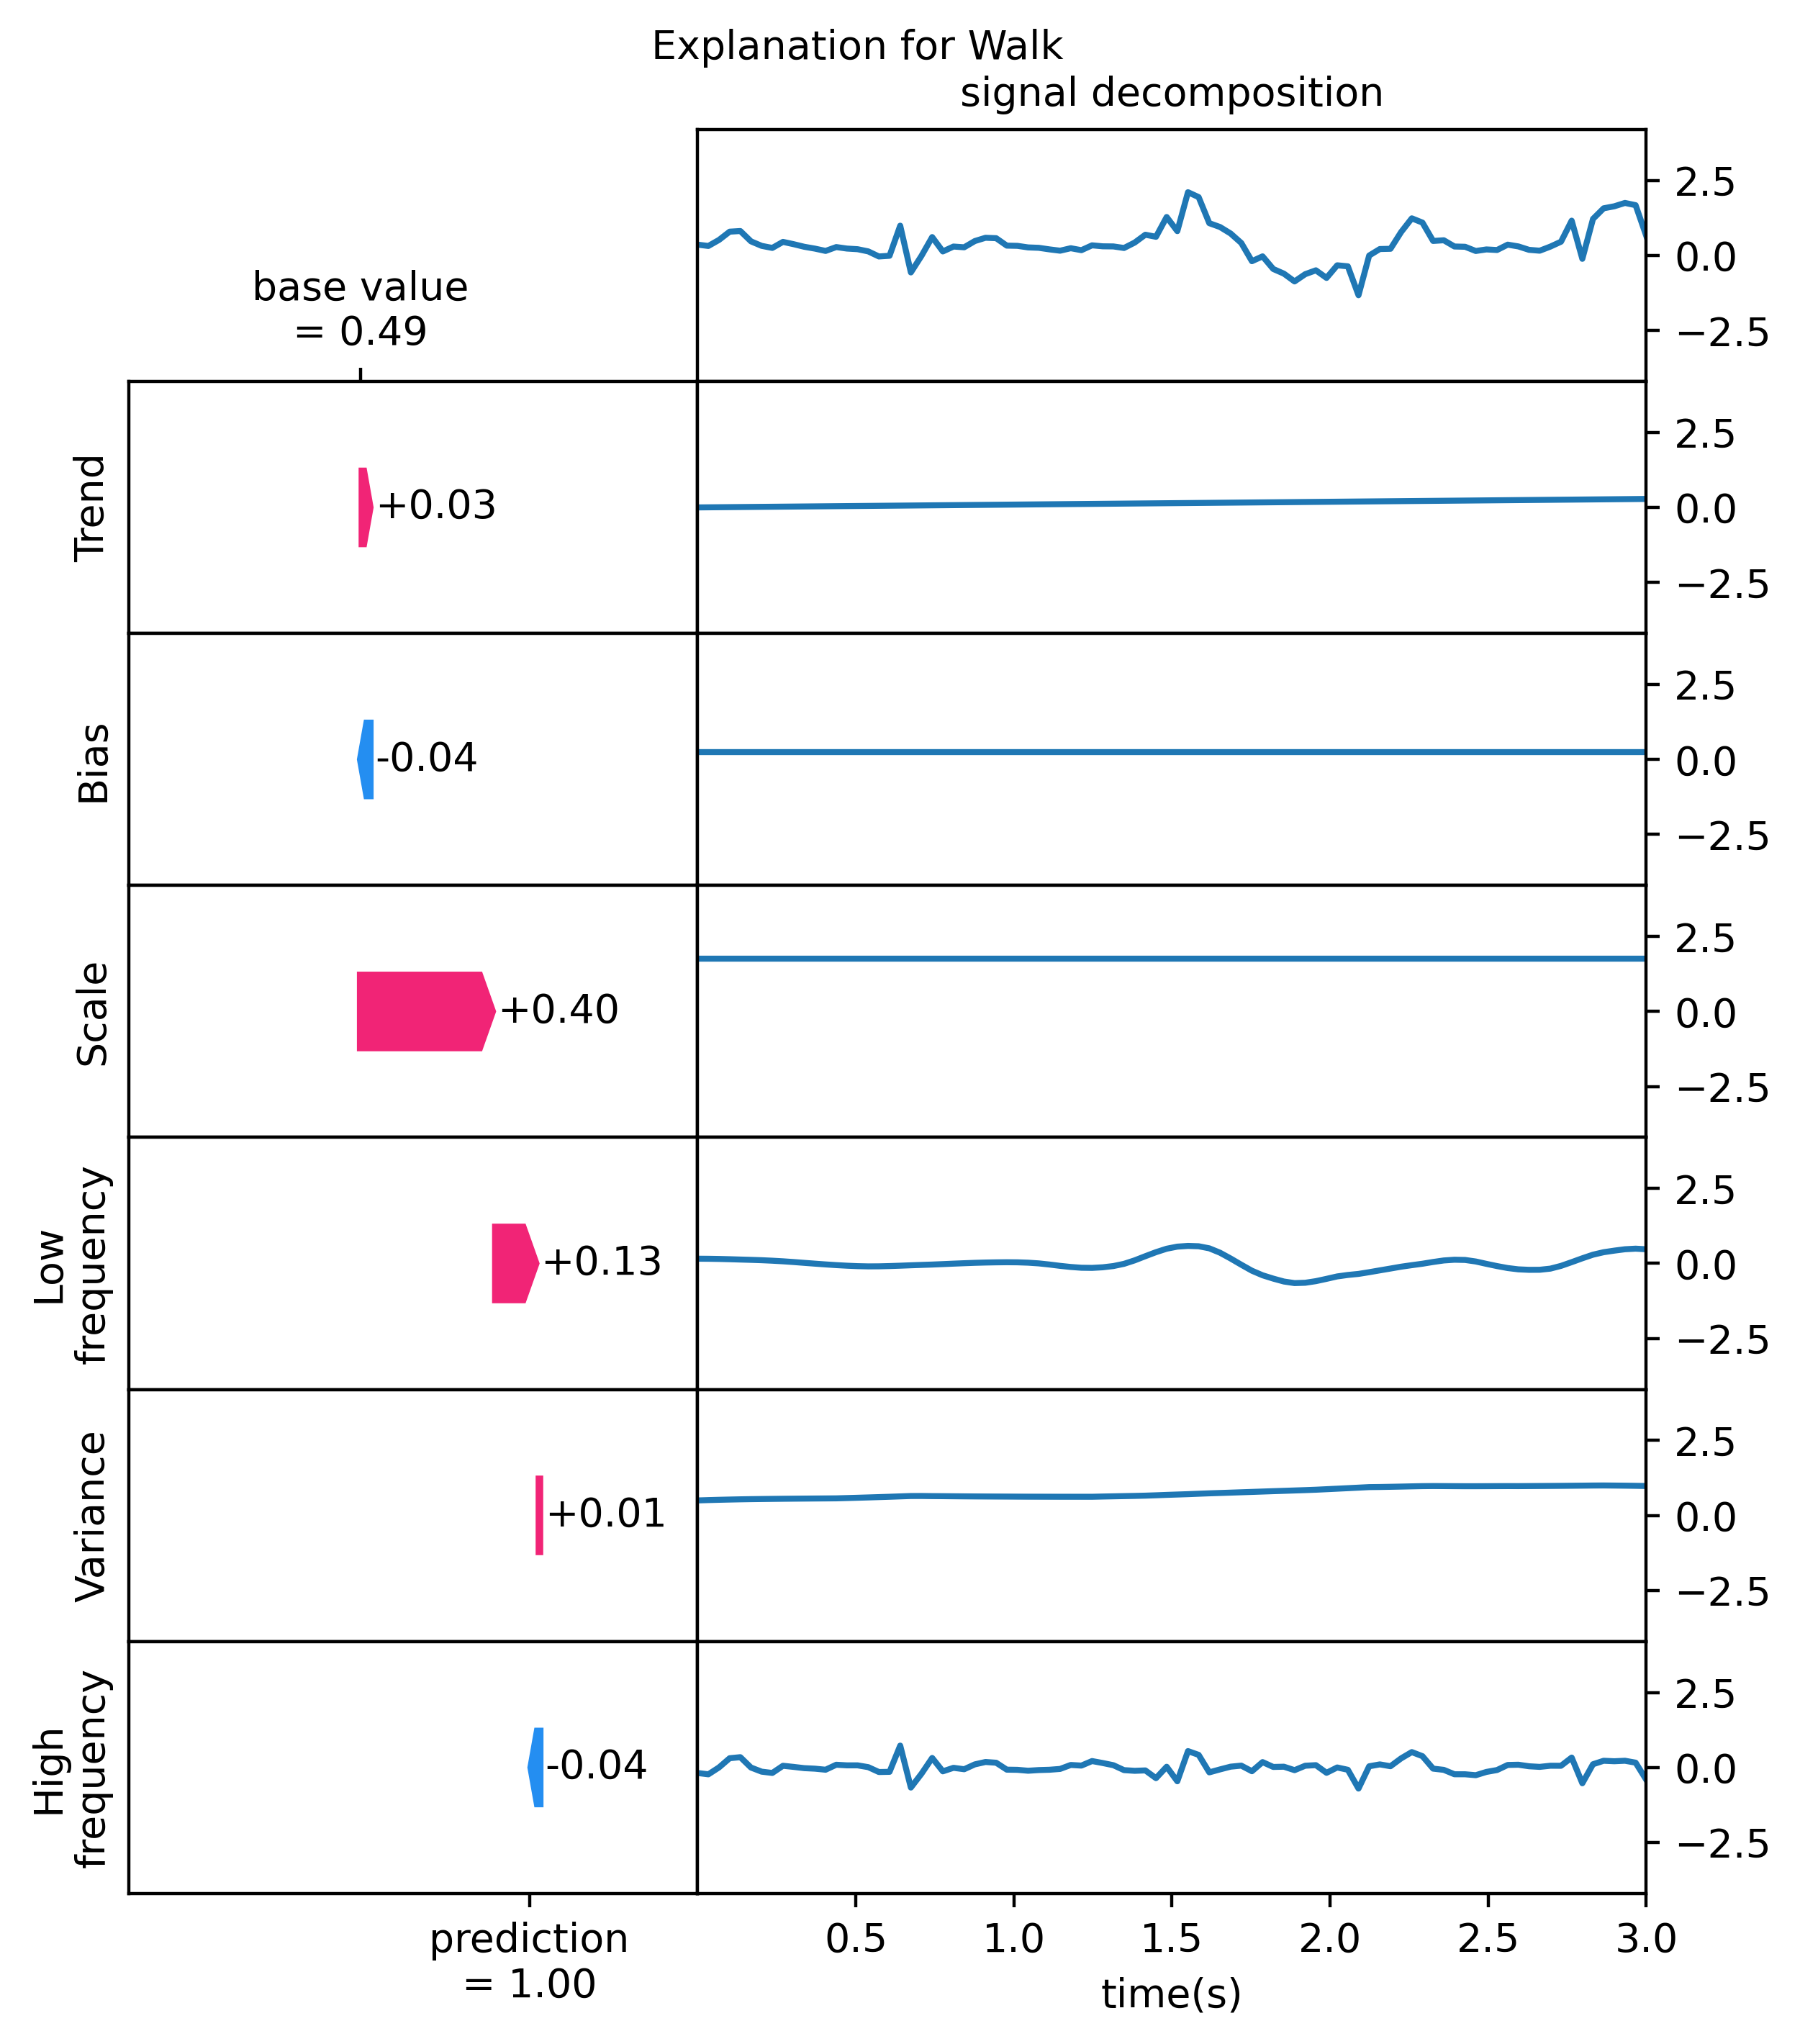

In [16]:
# Plot local explanation
if dataset in ['opportunity_uni', 'fordA']:
    shap_select, base_value_select = shap_values[sample_select, :, class_select], base_values[sample_select, class_select]
    shap_lims=[-0.2, 1.5]
else:
    shap_select, base_value_select = shap_values[sample_select, :, 0], base_values[sample_select]
    shap_lims=[-180, 180]
plot_shap_decomposition(t, X_test[sample_select][:, 0], y_pred, x_components, 
                        components, base_value_select, shap_select,
                        class_selected=class_label_selected,
                        figsize=(6, 7), dpi=400, ylims=ylims, xlabel='time(s)',
                        shap_lims=shap_lims);